Download dataset langsung dari GitHub

In [1]:
!git clone --depth 1 https://github.com/zhangleino1/WIFI-SCI-Indoor-Positioning.git

Cloning into 'WIFI-SCI-Indoor-Positioning'...
remote: Enumerating objects: 296, done.
remote: Counting objects: 100% (296/296), done.
remote: Compressing objects: 100% (294/294), done.
remote: Total 296 (delta 2), reused 283 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (296/296), 17.58 MiB | 64.75 MiB/s, done.
Resolving deltas: 100% (2/2), done.


Periksa Python, PyTorch, dan GPU

In [2]:
import sys, os, re, shutil, subprocess, copy, random
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import butter, sosfiltfilt, detrend
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.model_selection import train_test_split

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Python:', sys.version.split()[0])
print('PyTorch:', torch.__version__)
print('Perangkat:', DEVICE)
print('Status: Python siap.')

Python: 3.13.15
PyTorch: 2.11.0+cu130
Perangkat: cuda
Status: Python siap.


Hubungkan Google Drive dan membuat folder proyek

In [3]:
from google.colab import drive
drive.mount('/content/drive')

PROJECT = Path('/content/drive/MyDrive/Project_UTS_CSI_Localization')
for subfolder in ['dataset', 'notebook', 'models', 'results', 'laporan']:
    (PROJECT / subfolder).mkdir(parents=True, exist_ok=True)
print('Folder siap:', PROJECT)
print('Subfolder:', [p.name for p in PROJECT.iterdir() if p.is_dir()])

Mounted at /content/drive
Folder siap: /content/drive/MyDrive/Project_UTS_CSI_Localization
Subfolder: ['dataset', 'notebook', 'models', 'results', 'laporan']


In [4]:
REPO_URL = 'https://github.com/zhangleino1/WIFI-SCI-Indoor-Positioning.git'
LOCAL_REPO = Path('/content/wifi_csi_indoor_source')
DATA_DIR = PROJECT / 'dataset' / 'wifi_csi_sample'

existing = list(DATA_DIR.glob('antenna_*.csv')) if DATA_DIR.exists() else []
if len(existing) < 270:
    if not (LOCAL_REPO / 'dataset').exists():
        subprocess.run(['git', 'clone', '--depth', '1', REPO_URL, str(LOCAL_REPO)], check=True)
    DATA_DIR.mkdir(parents=True, exist_ok=True)
    for src in (LOCAL_REPO / 'dataset').glob('antenna_*.csv'):
        shutil.copy2(src, DATA_DIR / src.name)

files = sorted(DATA_DIR.glob('antenna_*.csv'))
print('Jumlah file CSI:', len(files))
print('Contoh:', [f.name for f in files[:5]])
assert len(files) >= 3, 'Tidak ada data CSV yang terunduh.'
print('Unduh dan penyimpanan dataset selesai!')

Jumlah file CSI: 270
Contoh: ['antenna_1_0_0.csv', 'antenna_1_0_1.csv', 'antenna_1_0_2.csv', 'antenna_1_0_3.csv', 'antenna_1_0_4.csv']
Unduh dan penyimpanan dataset selesai!


Data Exploration

Nama file: antenna_1_0_0.csv
Bentuk tabel: (60, 61)
5 kolom awal: ['amplitude_0', 'amplitude_1', 'amplitude_2', 'amplitude_3', 'amplitude_4']
5 kolom akhir: ['phase_26', 'phase_27', 'phase_28', 'phase_29', 'timestamp']


,amplitude_0,amplitude_1,amplitude_2,amplitude_3,amplitude_4,amplitude_5,amplitude_6,amplitude_7,amplitude_8,amplitude_9,...,phase_21,phase_22,phase_23,phase_24,phase_25,phase_26,phase_27,phase_28,phase_29,timestamp
0,14.402824,20.994419,18.154452,22.173757,26.351916,27.268077,28.426380,29.745494,31.005523,29.851649,...,-2.582993,-2.668237,2.773244,2.455863,1.781890,0.973620,0.416065,-0.568525,-1.048393,0.000000
1,11.967229,19.607658,17.957980,21.620599,25.065863,26.799485,27.942978,29.082412,30.184247,29.134120,...,-1.349482,-1.409421,-2.143256,-2.424581,-3.045734,2.461071,1.951303,1.025932,0.571337,0.002533
2,13.581042,20.456947,19.011012,22.230652,26.000712,26.931469,27.905759,29.870213,30.359000,29.665749,...,2.193467,2.060754,1.392386,1.053764,0.414507,-0.426627,-1.004067,-1.942864,-2.417343,0.005073


Jumlah titik koordinat dengan 3 antena: 90


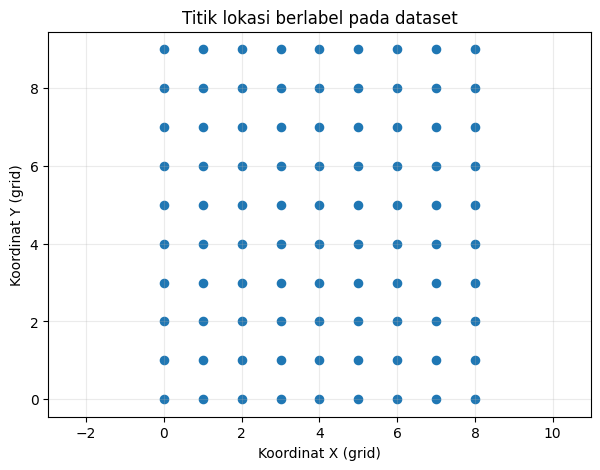

In [5]:
one = DATA_DIR / 'antenna_1_0_0.csv'
if not one.exists():
    one = files[0]
df = pd.read_csv(one)
print('Nama file:', one.name)
print('Bentuk tabel:', df.shape)
print('5 kolom awal:', df.columns[:5].tolist())
print('5 kolom akhir:', df.columns[-5:].tolist())
display(df.head(3))

locations = {}
pattern = re.compile(r'antenna_(\d+)_(-?\d+(?:\.\d+)?)_(-?\d+(?:\.\d+)?)\.csv$')
for f in files:
    m = pattern.fullmatch(f.name)
    if m is None:
        continue
    ant, x, y = int(m[1]), float(m[2]), float(m[3])
    locations.setdefault((x, y), {})[ant] = f
complete_locations = sorted(k for k, v in locations.items() if {1, 2, 3}.issubset(v))
print('Jumlah titik koordinat dengan 3 antena:', len(complete_locations))
assert len(complete_locations) >= 10, 'Titik lengkap terlalu sedikit. Periksa folder dataset.'

xy = np.array(complete_locations)
plt.figure(figsize=(7, 5))
plt.scatter(xy[:, 0], xy[:, 1], s=35)
plt.xlabel('Koordinat X (grid)')
plt.ylabel('Koordinat Y (grid)')
plt.title('Titik lokasi berlabel pada dataset')
plt.grid(alpha=0.25)
plt.axis('equal')
plt.show()

Preprocessing CSI: filtering, phase sanitization, dan penyusunan tensor

In [7]:
WINDOW = 15
STRIDE = 5
SOS = butter(3, 0.25, btype='lowpass', output='sos')

def read_and_preprocess_one_antenna(filepath):
    df = pd.read_csv(filepath)
    amp_cols = [f'amplitude_{i}' for i in range(30)]
    phase_cols = [f'phase_{i}' for i in range(30)]
    needed = amp_cols + phase_cols
    missing = [c for c in needed if c not in df.columns]
    if missing:
        raise ValueError(f'Kolom CSI kurang dalam {filepath.name}: {missing[:3]}')

    # Ubah nilai invalid (NaN, inf, -inf, atau teks) menjadi NaN.
    clean = df[needed].apply(pd.to_numeric, errors='coerce')
    clean = clean.replace([np.inf, -np.inf], np.nan)
    n_invalid = int(clean.isna().sum().sum())

    # Isi celah hanya dari data rekaman antena yang sama, sepanjang waktu.
    if n_invalid:
        print(f'[Perbaikan CSI] {filepath.name}: {n_invalid} nilai invalid -> interpolasi temporal')
        clean = clean.interpolate(method='linear', axis=0, limit_direction='both')

    # Jika satu kolom seluruhnya tidak valid, jangan diam-diam membuat data palsu.
    if clean.isna().any().any():
        broken = clean.columns[clean.isna().any()].tolist()
        raise ValueError(f'Data tidak cukup untuk interpolasi dalam {filepath.name}: {broken}')

    amp = clean[amp_cols].to_numpy(dtype=np.float32)
    phase = clean[phase_cols].to_numpy(dtype=np.float32)
    if not (np.isfinite(amp).all() and np.isfinite(phase).all()):
        raise ValueError(f'Masih ada nilai invalid setelah perbaikan dalam {filepath.name}')

    amp_filt = sosfiltfilt(SOS, amp, axis=0).astype(np.float32)
    phase_unwrap = np.unwrap(phase, axis=1)
    phase_clean = detrend(phase_unwrap, axis=1, type='linear').astype(np.float32)
    return amp_filt, phase_clean

X_chunks, y_chunks, group_chunks = [], [], []
for loc_id, (x, y) in enumerate(complete_locations):
    channels = []
    for antenna in (1, 2, 3):
        amp, ph = read_and_preprocess_one_antenna(locations[(x, y)][antenna])
        channels.extend([amp, ph])
    usable = min(a.shape[0] for a in channels)
    if usable < WINDOW:
        continue
    cube = np.stack([a[:usable] for a in channels], axis=0) # (6, time, 30)
    for start in range(0, usable-WINDOW+1, STRIDE):
        X_chunks.append(cube[:, start:start+WINDOW, :])
        y_chunks.append([x, y])
        group_chunks.append(loc_id)

X = np.stack(X_chunks).astype(np.float32)
y = np.array(y_chunks, dtype=np.float32)
groups = np.array(group_chunks)
print('Tensor X:', X.shape, '(jumlah sampel, 6 channel, 15 waktu, 30 subcarrier)')
print('Koordinat y:', y.shape)
print('Lokasi unik:', len(np.unique(groups)))
assert X.ndim == 4 and X.shape[1:] == (6, WINDOW, 30)
assert len(X) == len(y) == len(groups)

[Perbaikan CSI] antenna_2_0_4.csv: 1 nilai invalid -> interpolasi temporal
[Perbaikan CSI] antenna_2_0_5.csv: 1 nilai invalid -> interpolasi temporal
[Perbaikan CSI] antenna_3_0_9.csv: 1 nilai invalid -> interpolasi temporal
[Perbaikan CSI] antenna_2_1_1.csv: 1 nilai invalid -> interpolasi temporal
[Perbaikan CSI] antenna_1_1_4.csv: 1 nilai invalid -> interpolasi temporal
[Perbaikan CSI] antenna_2_1_4.csv: 2 nilai invalid -> interpolasi temporal
[Perbaikan CSI] antenna_2_1_5.csv: 12 nilai invalid -> interpolasi temporal
[Perbaikan CSI] antenna_2_1_6.csv: 1 nilai invalid -> interpolasi temporal
[Perbaikan CSI] antenna_2_1_7.csv: 1 nilai invalid -> interpolasi temporal
[Perbaikan CSI] antenna_2_1_9.csv: 7 nilai invalid -> interpolasi temporal
[Perbaikan CSI] antenna_2_2_0.csv: 1 nilai invalid -> interpolasi temporal
[Perbaikan CSI] antenna_2_2_1.csv: 5 nilai invalid -> interpolasi temporal
[Perbaikan CSI] antenna_2_2_2.csv: 3 nilai invalid -> interpolasi temporal
[Perbaikan CSI] antenna_

Split data per lokasi dan normalisasi

In [23]:
from sklearn.model_selection import train_test_split
import numpy as np
import pandas as pd

# Batas zona yang sama dengan Confusion Matrix
X_BOUNDARY = 4.5
Y_BOUNDARY = 4.5

def get_zone(coords):
    coords = np.asarray(coords)
    return (
        (coords[:, 0] > X_BOUNDARY).astype(int)
        + 2 * (coords[:, 1] > Y_BOUNDARY).astype(int)
    )

# Ambil satu koordinat untuk setiap grup lokasi
group_ids = np.unique(groups)

group_coords = np.array([
    y[np.where(groups == gid)[0][0]]
    for gid in group_ids
])

group_zones = get_zone(group_coords)

print("Distribusi seluruh lokasi:")
print(pd.Series(group_zones).value_counts().sort_index())

# Stratifikasi pada tingkat lokasi, bukan window
train_ids, rem_ids = train_test_split(
    group_ids,
    test_size=0.30,
    random_state=SEED,
    stratify=group_zones
)

zone_by_group = dict(zip(group_ids, group_zones))

remaining_zones = np.array([
    zone_by_group[gid] for gid in rem_ids
])

val_ids, test_ids = train_test_split(
    rem_ids,
    test_size=0.50,
    random_state=SEED,
    stratify=remaining_zones
)

# Cegah lokasi yang sama masuk ke beberapa split
assert not (
    set(train_ids) & set(val_ids)
    or set(train_ids) & set(test_ids)
    or set(val_ids) & set(test_ids)
)

mask_tr = np.isin(groups, train_ids)
mask_va = np.isin(groups, val_ids)
mask_te = np.isin(groups, test_ids)

X_train, y_train = X[mask_tr], y[mask_tr]
X_val, y_val = X[mask_va], y[mask_va]
X_test, y_test = X[mask_te], y[mask_te]

# Normalisasi hanya berdasarkan training
mean = X_train.mean(
    axis=(0, 2, 3), keepdims=True
)
std = X_train.std(
    axis=(0, 2, 3), keepdims=True
)

std = np.where(std < 1e-6, 1.0, std)

X_train = ((X_train - mean) / std).astype(np.float32)
X_val = ((X_val - mean) / std).astype(np.float32)
X_test = ((X_test - mean) / std).astype(np.float32)

print("\n=== DISTRIBUSI ZONA BARU ===")

for name, targets in [
    ("Training", y_train),
    ("Validation", y_val),
    ("Testing", y_test)
]:
    counts = np.bincount(
        get_zone(targets),
        minlength=4
    )

    print(
        name,
        dict(zip(["A", "B", "C", "D"], counts))
    )

print("\nSTRATIFIED SPLIT BERHASIL!")


Distribusi seluruh lokasi:
0    25
1    20
2    25
3    20
Name: count, dtype: int64

=== DISTRIBUSI ZONA BARU ===
Training {'A': np.int64(170), 'B': np.int64(140), 'C': np.int64(180), 'D': np.int64(140)}
Validation {'A': np.int64(40), 'B': np.int64(30), 'C': np.int64(30), 'D': np.int64(30)}
Testing {'A': np.int64(40), 'B': np.int64(30), 'C': np.int64(40), 'D': np.int64(30)}

STRATIFIED SPLIT BERHASIL!


Visualisasi CSI sesudah preprocessing

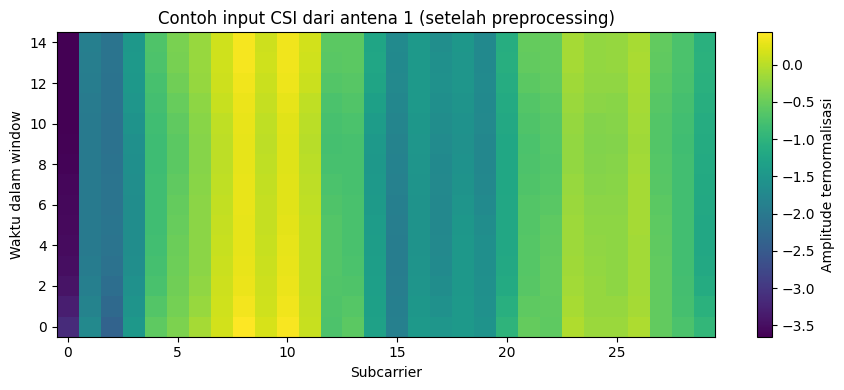

In [24]:
plt.figure(figsize=(9, 4))
plt.imshow(X_train[0, 0], aspect='auto', cmap='viridis', origin='lower')
plt.colorbar(label='Amplitude ternormalisasi')
plt.xlabel('Subcarrier')
plt.ylabel('Waktu dalam window')
plt.title('Contoh input CSI dari antena 1 (setelah preprocessing)')
plt.tight_layout()
plt.savefig(PROJECT/'results'/'contoh_csi_preprocessing.png', dpi=160)
plt.show()

Definisikan model MLP dan CNN-LSTM

In [25]:
def loader_from_arrays(features, targets, shuffle=False):
    ds = TensorDataset(torch.from_numpy(features), torch.from_numpy(targets))
    return DataLoader(ds, batch_size=32, shuffle=shuffle, num_workers=0)

train_loader = loader_from_arrays(X_train, y_train, shuffle=True)
val_loader = loader_from_arrays(X_val, y_val)
test_loader = loader_from_arrays(X_test, y_test)

class MLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(), nn.Linear(6*WINDOW*30, 256), nn.ReLU(),
            nn.Dropout(0.2), nn.Linear(256, 128), nn.ReLU(),
            nn.Linear(128, 2)
        )
    def forward(self, x):
        return self.net(x)

class CNNLSTM(nn.Module):
    def __init__(self):
        super().__init__()
        self.cnn = nn.Sequential(
            nn.Conv2d(6, 16, kernel_size=3, padding=1), nn.ReLU(),
            nn.Conv2d(16, 32, kernel_size=3, padding=1), nn.ReLU(),
            nn.AdaptiveAvgPool2d((WINDOW, 5))
        )
        self.lstm = nn.LSTM(input_size=32*5, hidden_size=64, batch_first=True)
        self.regressor = nn.Linear(64, 2)
    def forward(self, x):
        x = self.cnn(x)                 # (B,32,T,5)
        x = x.permute(0,2,1,3).contiguous().flatten(2)  # (B,T,160)
        _, (h, _) = self.lstm(x)
        return self.regressor(h[-1])

for name, model in [('MLP', MLP()), ('CNN-LSTM', CNNLSTM())]:
    with torch.no_grad():
        pred = model(torch.zeros(2, 6, WINDOW, 30))
    print(name, 'output:', tuple(pred.shape))

MLP output: (2, 2)
CNN-LSTM output: (2, 2)


Training dua model Deep Learning (MLP dan CNN-LSTM).

In [27]:
EPOCHS = 20

def evaluate_loss(model, loader, loss_fn):
    model.eval()
    total = count = 0
    with torch.no_grad():
        for xb, yb in loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            value = loss_fn(model(xb), yb)
            total += value.item()*len(xb)
            count += len(xb)
    return total/max(1,count)

def train_model(model, name):
    model = model.to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    loss_fn = nn.SmoothL1Loss()
    best_val = float('inf')
    best_weights = None
    wait = 0
    history = {'train':[], 'val':[]}
    for epoch in range(1, EPOCHS+1):
        model.train()
        total = 0.0
        for xb, yb in train_loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            optimizer.zero_grad()
            loss = loss_fn(model(xb), yb)
            loss.backward()
            optimizer.step()
            total += loss.item()*len(xb)
        train_loss = total / len(train_loader.dataset)
        val_loss = evaluate_loss(model, val_loader, loss_fn)
        history['train'].append(train_loss)
        history['val'].append(val_loss)
        print(f'{name} | Epoch {epoch:02d} | train_loss={train_loss:.4f} | val_loss={val_loss:.4f}')
        if val_loss < best_val - 1e-5:
            best_val = val_loss
            best_weights = copy.deepcopy(model.state_dict())
            wait = 0
        else:
            wait += 1
            if wait >= 6:
                print('Early stopping:', name)
                break
    model.load_state_dict(best_weights)
    torch.save(model.state_dict(), PROJECT/'models'/f'{name.replace("-", "_")}.pt')
    return model, history

mlp_model, mlp_history = train_model(MLP(), 'MLP')
cnn_lstm_model, cnn_history = train_model(CNNLSTM(), 'CNN-LSTM')
print('Model selesai dilatih dan disimpan.')

MLP | Epoch 01 | train_loss=1.6365 | val_loss=1.8532
MLP | Epoch 02 | train_loss=0.8503 | val_loss=1.5584
MLP | Epoch 03 | train_loss=0.5599 | val_loss=1.6607
MLP | Epoch 04 | train_loss=0.4206 | val_loss=1.6496
MLP | Epoch 05 | train_loss=0.3461 | val_loss=1.7015
MLP | Epoch 06 | train_loss=0.2679 | val_loss=1.6649
MLP | Epoch 07 | train_loss=0.2379 | val_loss=1.7466
MLP | Epoch 08 | train_loss=0.2004 | val_loss=1.7259
Early stopping: MLP
CNN-LSTM | Epoch 01 | train_loss=3.0376 | val_loss=2.3581
CNN-LSTM | Epoch 02 | train_loss=1.9757 | val_loss=1.9107
CNN-LSTM | Epoch 03 | train_loss=1.6808 | val_loss=1.9014
CNN-LSTM | Epoch 04 | train_loss=1.4925 | val_loss=1.9063
CNN-LSTM | Epoch 05 | train_loss=1.3605 | val_loss=1.8733
CNN-LSTM | Epoch 06 | train_loss=1.3114 | val_loss=1.9002
CNN-LSTM | Epoch 07 | train_loss=1.2660 | val_loss=1.9483
CNN-LSTM | Epoch 08 | train_loss=1.2301 | val_loss=1.9072
CNN-LSTM | Epoch 09 | train_loss=1.2044 | val_loss=1.8968
CNN-LSTM | Epoch 10 | train_loss=1

Uji final pada lokasi yang tidak masuk training

In [28]:
def test_model(model, name):
    model.eval()
    preds, actuals = [], []
    with torch.no_grad():
        for xb, yb in test_loader:
            output = model(xb.to(DEVICE)).cpu().numpy()
            preds.append(output)
            actuals.append(yb.numpy())
    pred = np.concatenate(preds)
    actual = np.concatenate(actuals)
    distances = np.linalg.norm(pred - actual, axis=1)
    summary = {
        'Model': name,
        'Mean error (grid)': float(distances.mean()),
        'Median error (grid)': float(np.median(distances)),
        'P90 error (grid)': float(np.quantile(distances, .90)),
    }
    return summary, pred, actual

results, predictions = [], {}
for name, model in [('MLP',mlp_model), ('CNN-LSTM',cnn_lstm_model)]:
    summary, pred, true = test_model(model, name)
    results.append(summary)
    predictions[name] = pred

comparison = pd.DataFrame(results).sort_values('Mean error (grid)')
display(comparison)
comparison.to_csv(PROJECT/'results'/'model_comparison.csv', index=False)
print('Tabel tersimpan di folder results.')

,Model,Mean error (grid),Median error (grid),P90 error (grid)
1,CNN-LSTM,3.369374,3.611019,5.108917
0,MLP,3.542555,3.712326,5.568629


Tabel tersimpan di folder results.


Grafik loss, peta posisi, dan demo inferensi

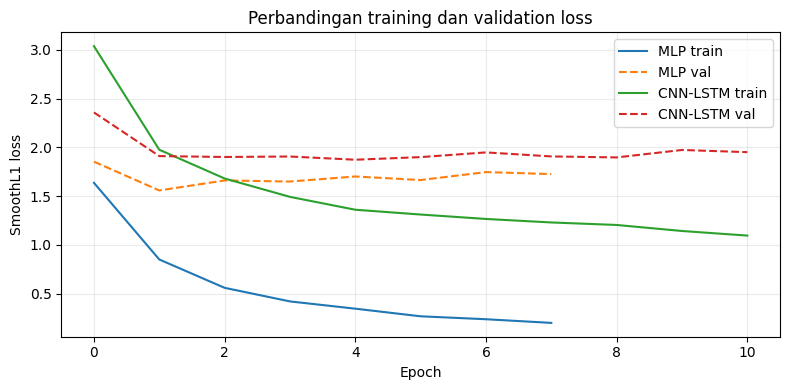

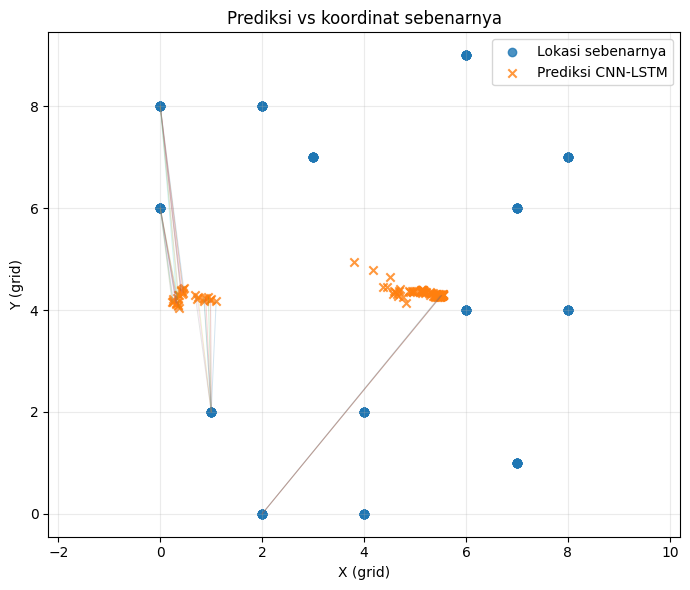

DEMO INFERENSI
Koordinat sebenarnya: [0.0, 6.0]
Prediksi MLP: [0.3700000047683716, 5.960000038146973]
Prediksi CNN-LSTM: [0.3199999928474426, 4.150000095367432]


In [29]:
plt.figure(figsize=(8,4))
for name,hist in [('MLP',mlp_history),('CNN-LSTM',cnn_history)]:
    plt.plot(hist['train'], label=f'{name} train')
    plt.plot(hist['val'], '--', label=f'{name} val')
plt.xlabel('Epoch')
plt.ylabel('SmoothL1 loss')
plt.title('Perbandingan training dan validation loss')
plt.legend()
plt.grid(alpha=.25)
plt.tight_layout()
plt.savefig(PROJECT/'results'/'loss_comparison.png', dpi=160)
plt.show()

better = comparison.iloc[0]['Model']
best_pred = predictions[better]
plt.figure(figsize=(7,6))
plt.scatter(y_test[:,0], y_test[:,1], label='Lokasi sebenarnya', alpha=.8)
plt.scatter(best_pred[:,0], best_pred[:,1], label='Prediksi '+better, marker='x', alpha=.8)
for a,b in zip(y_test[:35], best_pred[:35]):
    plt.plot([a[0],b[0]],[a[1],b[1]],alpha=.2,linewidth=.7)
plt.xlabel('X (grid)')
plt.ylabel('Y (grid)')
plt.title('Prediksi vs koordinat sebenarnya')
plt.legend()
plt.grid(alpha=.25)
plt.axis('equal')
plt.tight_layout()
plt.savefig(PROJECT/'results'/'localization_scatter.png', dpi=160)
plt.show()

idx=0
print('DEMO INFERENSI')
print('Koordinat sebenarnya:', y_test[idx].tolist())
print('Prediksi MLP:', predictions['MLP'][idx].round(2).tolist())
print('Prediksi CNN-LSTM:', predictions['CNN-LSTM'][idx].round(2).tolist())

Periksa hasil awal dan backup file

In [30]:
required = ['PROJECT', 'DATA_DIR', 'X', 'y', 'groups', 'locations',
            'complete_locations', 'WINDOW', 'STRIDE', 'mask_tr',
            'mask_va', 'mask_te', 'MLP', 'DEVICE', 'EPOCHS']
missing = [key for key in required if key not in globals()]
if missing:
    raise RuntimeError('Jalankan sel-sel notebook sebelumnya terlebih dahulu: ' + ', '.join(missing))

for filename in ['MLP.pt', 'CNN_LSTM.pt']:
    f = PROJECT / 'models' / filename
    print(filename, 'tersimpan:', f.is_file())

baseline_csv = PROJECT / 'results' / 'model_comparison.csv'
if not baseline_csv.is_file():
    raise FileNotFoundError('File model_comparison.csv belum ditemukan. Jalankan evaluasi Bagian 10 dahulu.')

print('\nHASIL MODEL AWAL:')
display(pd.read_csv(baseline_csv))
print('Variabel data dan split tersedia. Lanjutkan ke Bagian 14.')

MLP.pt tersimpan: True
CNN_LSTM.pt tersimpan: True

HASIL MODEL AWAL:


,Model,Mean error (grid),Median error (grid),P90 error (grid)
0,CNN-LSTM,3.369374,3.611019,5.108917
1,MLP,3.542555,3.712326,5.568629


Variabel data dan split tersedia. Lanjutkan ke Bagian 14.


Siapkan dataset tanpa Butterworth untuk ablation study

In [31]:
from scipy.signal import detrend


def read_antenna_without_amp_filter(filepath):
    df = pd.read_csv(filepath)
    amp_cols = [f'amplitude_{i}' for i in range(30)]
    phase_cols = [f'phase_{i}' for i in range(30)]
    needed = amp_cols + phase_cols
    missing_cols = [col for col in needed if col not in df.columns]
    if missing_cols:
        raise ValueError(f'Kolom tidak ditemukan di {filepath.name}: {missing_cols}')

    clean = df[needed].apply(pd.to_numeric, errors='coerce')
    clean = clean.replace([np.inf, -np.inf], np.nan)
    if clean.isna().any().any():
        clean = clean.interpolate(method='linear', axis=0, limit_direction='both')
    if clean.isna().any().any():
        raise ValueError(f'Masih ada nilai invalid pada {filepath.name}')

    amp = clean[amp_cols].to_numpy(dtype=np.float32)  # Tanpa Butterworth
    phase = clean[phase_cols].to_numpy(dtype=np.float32)
    phase_clean = detrend(np.unwrap(phase, axis=1), axis=1, type='linear').astype(np.float32)
    if not np.isfinite(amp).all() or not np.isfinite(phase_clean).all():
        raise ValueError(f'Nilai CSI invalid sesudah pemrosesan di {filepath.name}')
    return amp, phase_clean

raw_windows, raw_labels, raw_groups = [], [], []
for loc_id, (x, y_) in enumerate(complete_locations):
    channels = []
    for ant in (1, 2, 3):
        amp, phase = read_antenna_without_amp_filter(locations[(x, y_)][ant])
        channels.extend((amp, phase))
    usable = min(ch.shape[0] for ch in channels)
    if usable < WINDOW:
        continue
    cube = np.stack([ch[:usable] for ch in channels], axis=0)
    for start in range(0, usable-WINDOW+1, STRIDE):
        raw_windows.append(cube[:, start:start+WINDOW, :])
        raw_labels.append((x, y_))
        raw_groups.append(loc_id)

X_no_filter = np.stack(raw_windows).astype(np.float32)
assert X_no_filter.shape == X.shape, 'Jumlah atau dimensi sampel berbeda.'
assert np.array_equal(np.asarray(raw_labels, dtype=np.float32), y), 'Label koordinat berbeda.'
assert np.array_equal(np.asarray(raw_groups), groups), 'Urutan lokasi berbeda.'

print('Dataset tanpa filtering:', X_no_filter.shape)
print('Dataset dengan filtering:', X.shape)
print('Rata-rata perubahan amplitudo:',
      round(float(np.mean(np.abs(X[:, 0::2] - X_no_filter[:, 0::2]))), 5))
print('Berhasil: label, urutan, dan split kedua skenario identik.')

Dataset tanpa filtering: (900, 6, 15, 30)
Dataset dengan filtering: (900, 6, 15, 30)
Rata-rata perubahan amplitudo: 0.37505
Berhasil: label, urutan, dan split kedua skenario identik.


Training ablation MLP (dua kondisi)

In [32]:
import copy
from torch.utils.data import DataLoader, TensorDataset

ABLATION_SEED = 2026
ABLATION_EPOCHS = int(EPOCHS)  # Sama: 20 pada notebook utama


def ablation_arrays(features):
    train = features[mask_tr]
    val = features[mask_va]
    test = features[mask_te]
    mu = train.mean(axis=(0, 2, 3), keepdims=True)
    sigma = train.std(axis=(0, 2, 3), keepdims=True)
    sigma = np.where(sigma < 1e-6, 1., sigma)
    return tuple(((part-mu)/sigma).astype(np.float32) for part in (train,val,test))


def ablation_loader(x_arr, y_arr, shuffle=False):
    generator = torch.Generator().manual_seed(ABLATION_SEED)
    return DataLoader(
        TensorDataset(torch.from_numpy(x_arr), torch.from_numpy(y_arr)),
        batch_size=32, shuffle=shuffle, generator=generator, num_workers=0
    )


def fit_ablation(features, description, file_suffix):
    np.random.seed(ABLATION_SEED)
    torch.manual_seed(ABLATION_SEED)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(ABLATION_SEED)

    xtr, xva, xte = ablation_arrays(features)
    tr_loader = ablation_loader(xtr, y[mask_tr], shuffle=True)
    va_loader = ablation_loader(xva, y[mask_va])
    te_loader = ablation_loader(xte, y[mask_te])

    model = MLP().to(DEVICE)
    loss_fn = nn.SmoothL1Loss()
    opt = torch.optim.Adam(model.parameters(), lr=1e-3)
    best_val = float('inf')
    best_state = None
    wait = 0
    history = {'train': [], 'val': []}

    for epoch in range(1, ABLATION_EPOCHS+1):
        model.train()
        tr_sum = 0.0
        for xb, yb in tr_loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            opt.zero_grad()
            loss = loss_fn(model(xb), yb)
            loss.backward()
            opt.step()
            tr_sum += loss.item()*len(xb)
        train_loss = tr_sum / len(tr_loader.dataset)

        model.eval()
        val_sum = 0.0
        with torch.no_grad():
            for xb, yb in va_loader:
                xb, yb = xb.to(DEVICE), yb.to(DEVICE)
                val_sum += loss_fn(model(xb), yb).item()*len(xb)
        val_loss = val_sum / len(va_loader.dataset)
        history['train'].append(train_loss)
        history['val'].append(val_loss)
        print(f'{description} | {epoch:02d} | train={train_loss:.4f} | val={val_loss:.4f}')

        if val_loss < best_val - 1e-5:
            best_val = val_loss
            best_state = copy.deepcopy(model.state_dict())
            wait = 0
        else:
            wait += 1
            if wait >= 6:
                print('Early stopping:', description)
                break

    model.load_state_dict(best_state)
    checkpoint = PROJECT/'models'/f'ablation_mlp_{file_suffix}.pt'
    torch.save(model.state_dict(), checkpoint)

    model.eval()
    pred, actual = [], []
    with torch.no_grad():
        for xb, yb in te_loader:
            pred.append(model(xb.to(DEVICE)).cpu().numpy())
            actual.append(yb.numpy())
    distances = np.linalg.norm(np.concatenate(pred)-np.concatenate(actual), axis=1)
    stats = {
        'Perlakuan': description,
        'Mean error (grid)': float(distances.mean()),
        'Median error (grid)': float(np.median(distances)),
        'P90 error (grid)': float(np.quantile(distances, .9)),
    }
    print('Checkpoint tersimpan:', checkpoint.name)
    return stats, history

ablation_stats = []
ablation_histories = {}
for data, title, suffix in [
    (X, 'Dengan Butterworth', 'dengan_filter'),
    (X_no_filter, 'Tanpa Butterworth', 'tanpa_filter')
]:
    row, hist = fit_ablation(data, title, suffix)
    ablation_stats.append(row)
    ablation_histories[title] = hist

ablation_table = pd.DataFrame(ablation_stats)
display(ablation_table)
ablation_table.to_csv(PROJECT/'results'/'ablation_mlp_filter.csv', index=False)
print('Ablation study selesai: ablation_mlp_filter.csv tersimpan.')

Dengan Butterworth | 01 | train=1.6587 | val=1.8403
Dengan Butterworth | 02 | train=0.8657 | val=1.6422
Dengan Butterworth | 03 | train=0.5319 | val=1.7262
Dengan Butterworth | 04 | train=0.3830 | val=1.6563
Dengan Butterworth | 05 | train=0.2901 | val=1.7511
Dengan Butterworth | 06 | train=0.2641 | val=1.7682
Dengan Butterworth | 07 | train=0.2467 | val=1.8489
Dengan Butterworth | 08 | train=0.2094 | val=1.7190
Early stopping: Dengan Butterworth
Checkpoint tersimpan: ablation_mlp_dengan_filter.pt
Tanpa Butterworth | 01 | train=1.6595 | val=1.8059
Tanpa Butterworth | 02 | train=0.8656 | val=1.6524
Tanpa Butterworth | 03 | train=0.5559 | val=1.7147
Tanpa Butterworth | 04 | train=0.3792 | val=1.6569
Tanpa Butterworth | 05 | train=0.2875 | val=1.7156
Tanpa Butterworth | 06 | train=0.2629 | val=1.8019
Tanpa Butterworth | 07 | train=0.2315 | val=1.8336
Tanpa Butterworth | 08 | train=0.2346 | val=1.6403
Tanpa Butterworth | 09 | train=0.2535 | val=1.7234
Tanpa Butterworth | 10 | train=0.1929 

,Perlakuan,Mean error (grid),Median error (grid),P90 error (grid)
0,Dengan Butterworth,3.563384,3.666789,5.470792
1,Tanpa Butterworth,3.345981,3.202155,5.248418


Ablation study selesai: ablation_mlp_filter.csv tersimpan.


grafik ablation

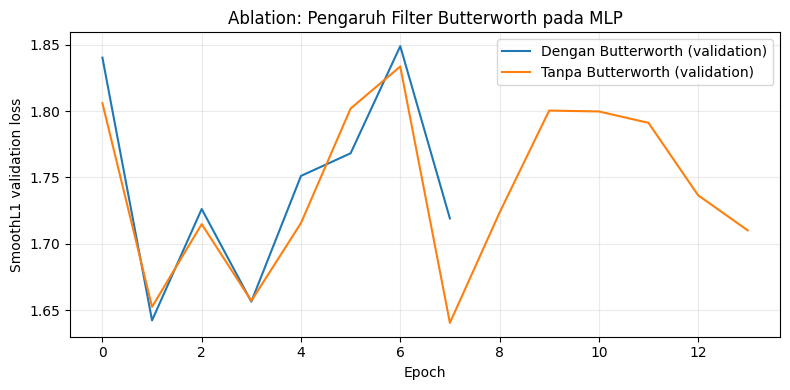

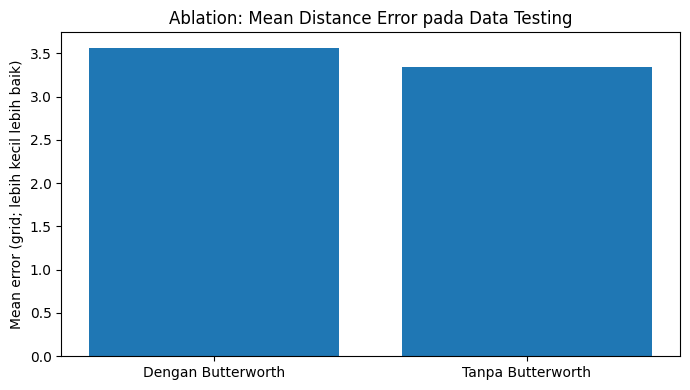

File eksperimen akhir:
 - ablation_mean_error.png
 - ablation_mlp_filter.csv
 - ablation_validation_loss.png
 - confusion_matrix_cnn_lstm.csv
 - confusion_matrix_cnn_lstm.png
 - confusion_matrix_mlp.csv
 - confusion_matrix_mlp.png
 - contoh_csi_preprocessing.png
 - localization_scatter.png
 - loss_comparison.png
 - model_comparison.csv
 - zone_classification_comparison.csv

Checkpoint:
 - CNN_LSTM.pt
 - MLP.pt
 - ablation_mlp_dengan_filter.pt
 - ablation_mlp_tanpa_filter.pt

CATATAN: Evaluasi memakai grid, bukan meter. Dataset GitHub merupakan subset demonstrasi.


In [33]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 4))
for name, hist in ablation_histories.items():
    plt.plot(hist['val'], label=f'{name} (validation)')
plt.xlabel('Epoch')
plt.ylabel('SmoothL1 validation loss')
plt.title('Ablation: Pengaruh Filter Butterworth pada MLP')
plt.legend()
plt.grid(alpha=.25)
plt.tight_layout()
plt.savefig(PROJECT/'results'/'ablation_validation_loss.png', dpi=160)
plt.show()

plt.figure(figsize=(7, 4))
plt.bar(ablation_table['Perlakuan'], ablation_table['Mean error (grid)'])
plt.ylabel('Mean error (grid; lebih kecil lebih baik)')
plt.title('Ablation: Mean Distance Error pada Data Testing')
plt.tight_layout()
plt.savefig(PROJECT/'results'/'ablation_mean_error.png', dpi=160)
plt.show()

print('File eksperimen akhir:')
for p in sorted((PROJECT/'results').glob('*')):
    print(' -', p.name)
print('\nCheckpoint:')
for p in sorted((PROJECT/'models').glob('*.pt')):
    print(' -', p.name)
print('\nCATATAN: Evaluasi memakai grid, bukan meter. Dataset GitHub merupakan subset demonstrasi.')

menampilkan hasil Ablation Study

In [34]:
from pathlib import Path
import pandas as pd

results_dir = Path(
    "/content/drive/MyDrive/"
    "Project_UTS_CSI_Localization/results"
)

print("=== FILE HASIL EKSPERIMEN ===")

for f in sorted(results_dir.glob("*ablation*")):
    print(f.name)

csv_file = results_dir / "ablation_mlp_filter.csv"

if csv_file.exists():
    print("\n=== HASIL ABLATION STUDY ===")
    hasil = pd.read_csv(csv_file)
    display(hasil)
    print("Ablation Study berhasil disimpan!")
else:
    print("File CSV ablation belum ditemukan.")


=== FILE HASIL EKSPERIMEN ===
ablation_mean_error.png
ablation_mlp_filter.csv
ablation_validation_loss.png

=== HASIL ABLATION STUDY ===


,Perlakuan,Mean error (grid),Median error (grid),P90 error (grid)
0,Dengan Butterworth,3.563384,3.666789,5.470792
1,Tanpa Butterworth,3.345981,3.202155,5.248418


Ablation Study berhasil disimpan!


In [19]:
from pathlib import Path
import shutil
from google.colab import files

PROJECT = Path(
    "/content/drive/MyDrive/Project_UTS_CSI_Localization"
)

RESULTS = PROJECT / "results"
MODELS = PROJECT / "models"

print("=== PEMERIKSAAN HASIL UTS ===")

for folder in [RESULTS, MODELS]:
    print(f"\nFolder: {folder.name}")

    if folder.exists():
        for f in sorted(folder.iterdir()):
            if f.is_file():
                print("OK:", f.name)
    else:
        print("PERINGATAN: Folder tidak ditemukan")

# ZIP khusus hasil grafik dan tabel
zip_path = shutil.make_archive(
    "/content/HASIL_EKSPERIMEN_UTS",
    "zip",
    root_dir=str(RESULTS)
)

print("\nBackup hasil dibuat:", zip_path)

files.download(zip_path)


=== PEMERIKSAAN HASIL UTS ===

Folder: results
OK: ablation_mean_error.png
OK: ablation_mlp_filter.csv
OK: ablation_validation_loss.png
OK: contoh_csi_preprocessing.png
OK: localization_scatter.png
OK: loss_comparison.png
OK: model_comparison.csv

Folder: models
OK: CNN_LSTM.pt
OK: MLP.pt
OK: ablation_mlp_dengan_filter.pt
OK: ablation_mlp_tanpa_filter.pt

Backup hasil dibuat: /content/HASIL_EKSPERIMEN_UTS.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Confusion Matrix untuk MLP dan CNN-LSTM (evaluasi 4 zona)

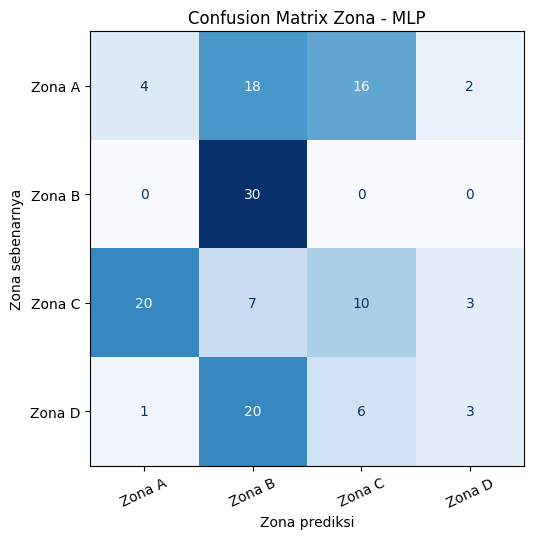


=== MLP ===


,Prediksi Zona A,Prediksi Zona B,Prediksi Zona C,Prediksi Zona D
Aktual Zona A,4,18,16,2
Aktual Zona B,0,30,0,0
Aktual Zona C,20,7,10,3
Aktual Zona D,1,20,6,3


Akurasi zona: 33.57%
Grafik tersimpan: confusion_matrix_mlp.png


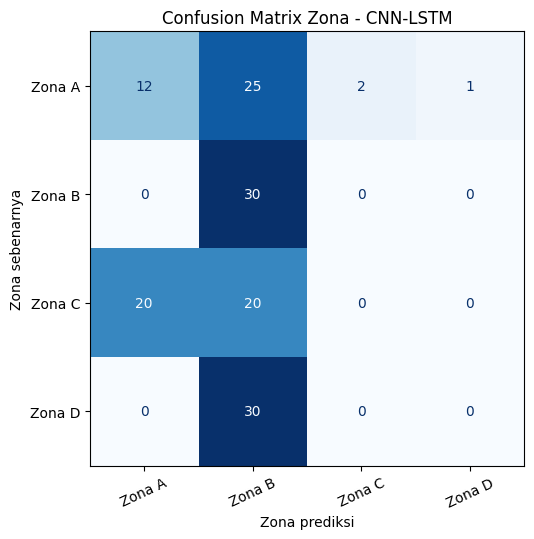


=== CNN-LSTM ===


,Prediksi Zona A,Prediksi Zona B,Prediksi Zona C,Prediksi Zona D
Aktual Zona A,12,25,2,1
Aktual Zona B,0,30,0,0
Aktual Zona C,20,20,0,0
Aktual Zona D,0,30,0,0


Akurasi zona: 30.00%
Grafik tersimpan: confusion_matrix_cnn_lstm.png

=== RINGKASAN PERBANDINGAN KLASIFIKASI ZONA ===


,Model,Total sampel testing,Akurasi zona (%),Precision macro,Recall macro,F1 macro
0,MLP,140,33.571,0.312,0.363,0.283
1,CNN-LSTM,140,30.000,0.165,0.325,0.194



Output tersimpan dalam: /content/drive/MyDrive/Project_UTS_CSI_Localization/results
Catatan: Akurasi zona adalah evaluasi tambahan. Ukuran utama lokalisasi tetap error jarak (grid).


In [35]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay,
                             accuracy_score, precision_recall_fscore_support)

# Periksa hasil testing dari Bagian 10; jangan menggunakan data training.
required = ['predictions', 'y_test', 'PROJECT']
missing = [name for name in required if name not in globals()]
if missing:
    raise RuntimeError('Variabel hilang: ' + ', '.join(missing) +
                       '. Jalankan lagi Bagian 10 di notebook yang sama.')

actual_xy = np.asarray(y_test, dtype=float)
if actual_xy.ndim != 2 or actual_xy.shape[1] != 2:
    raise ValueError(f'y_test harus berukuran (N, 2), bukan {actual_xy.shape}')
if not np.isfinite(actual_xy).all():
    raise ValueError('y_test mengandung nilai koordinat tidak valid.')

# Batas 4.5 grid: pemisah antara 4 dan 5 pada sumbu X maupun Y.
X_BOUNDARY = 4.5
Y_BOUNDARY = 4.5
ZONE_NAMES = ['Zona A', 'Zona B', 'Zona C', 'Zona D']
ZONE_IDS = list(range(4))

def coords_to_zone(points):
    points = np.asarray(points, dtype=float)
    if points.ndim != 2 or points.shape[1] != 2:
        raise ValueError(f'Koordinat harus (N,2), dapat {points.shape}')
    if not np.isfinite(points).all():
        raise ValueError('Koordinat mengandung NaN atau inf.')
    # 0=A (kiri bawah), 1=B (kanan bawah),
    # 2=C (kiri atas), 3=D (kanan atas)
    return ((points[:, 1] > Y_BOUNDARY).astype(int) * 2 +
            (points[:, 0] > X_BOUNDARY).astype(int))

zone_true = coords_to_zone(actual_xy)
results_dir = Path(PROJECT) / 'results'
results_dir.mkdir(parents=True, exist_ok=True)
all_stats = []

for model_name, filename in [
    ('MLP', 'mlp'),
    ('CNN-LSTM', 'cnn_lstm')
]:
    if model_name not in predictions:
        raise KeyError(f'Prediksi {model_name} belum tersedia: jalankan Bagian 10.')

    pred_xy = np.asarray(predictions[model_name], dtype=float)
    if pred_xy.shape != actual_xy.shape:
        raise ValueError(f'{model_name}: prediksi {pred_xy.shape} vs aktual {actual_xy.shape}')
    zone_pred = coords_to_zone(pred_xy)
    cm = confusion_matrix(zone_true, zone_pred, labels=ZONE_IDS)

    # Simpan angka mentah yang dibutuhkan untuk reproduksi laporan.
    cm_df = pd.DataFrame(
        cm,
        index=[f'Aktual {name}' for name in ZONE_NAMES],
        columns=[f'Prediksi {name}' for name in ZONE_NAMES]
    )
    cm_df.to_csv(results_dir / f'confusion_matrix_{filename}.csv')

    # Grafik PNG untuk laporan IEEE, satu grafik per model.
    fig, ax = plt.subplots(figsize=(6.4, 5.5))
    display_cm = ConfusionMatrixDisplay(cm, display_labels=ZONE_NAMES)
    display_cm.plot(ax=ax, cmap='Blues', colorbar=False,
                    values_format='d', xticks_rotation=25)
    ax.set_title(f'Confusion Matrix Zona - {model_name}')
    ax.set_xlabel('Zona prediksi')
    ax.set_ylabel('Zona sebenarnya')
    fig.tight_layout()
    png_file = results_dir / f'confusion_matrix_{filename}.png'
    fig.savefig(png_file, dpi=200, bbox_inches='tight')
    plt.show()

    precision, recall, f1, _ = precision_recall_fscore_support(
        zone_true, zone_pred, labels=ZONE_IDS,
        average='macro', zero_division=0
    )
    score = {
        'Model': model_name,
        'Total sampel testing': len(zone_true),
        'Akurasi zona (%)': 100 * accuracy_score(zone_true, zone_pred),
        'Precision macro': precision,
        'Recall macro': recall,
        'F1 macro': f1,
    }
    all_stats.append(score)
    print(f'\n=== {model_name} ===')
    display(cm_df)
    print(f"Akurasi zona: {score['Akurasi zona (%)']:.2f}%")
    print('Grafik tersimpan:', png_file.name)

summary = pd.DataFrame(all_stats)
summary.to_csv(results_dir / 'zone_classification_comparison.csv', index=False)
print('\n=== RINGKASAN PERBANDINGAN KLASIFIKASI ZONA ===')
display(summary.round(3))
print('\nOutput tersimpan dalam:', results_dir)
print('Catatan: Akurasi zona adalah evaluasi tambahan. Ukuran utama lokalisasi tetap error jarak (grid).')


memeriksa semua file hasil proyek UTS dan membuat backup hasil

In [36]:
import numpy as np
import pandas as pd
from sklearn.metrics import classification_report

zona_asli = coords_to_zone(y_test)

print("=== DISTRIBUSI ZONA SEBENARNYA ===")
print(pd.Series(zona_asli).value_counts().sort_index())

for name in ["MLP", "CNN-LSTM"]:
    zona_pred = coords_to_zone(predictions[name])

    print(f"\n=== HASIL {name} ===")

    print("Distribusi prediksi:")
    print(
        pd.Series(zona_pred)
        .value_counts()
        .sort_index()
    )

    print("\nClassification Report:")
    print(
        classification_report(
            zona_asli,
            zona_pred,
            labels=[0, 1, 2, 3],
            target_names=[
                "Zona A", "Zona B",
                "Zona C", "Zona D"
            ],
            zero_division=0
        )
    )

majority_accuracy = (
    pd.Series(zona_asli).value_counts().max()
    / len(zona_asli) * 100
)

print(
    "\nBaseline kelas mayoritas:",
    f"{majority_accuracy:.2f}%"
)


=== DISTRIBUSI ZONA SEBENARNYA ===
0    40
1    30
2    40
3    30
Name: count, dtype: int64

=== HASIL MLP ===
Distribusi prediksi:
0    25
1    75
2    32
3     8
Name: count, dtype: int64

Classification Report:
              precision    recall  f1-score   support

      Zona A       0.16      0.10      0.12        40
      Zona B       0.40      1.00      0.57        30
      Zona C       0.31      0.25      0.28        40
      Zona D       0.38      0.10      0.16        30

    accuracy                           0.34       140
   macro avg       0.31      0.36      0.28       140
weighted avg       0.30      0.34      0.27       140


=== HASIL CNN-LSTM ===
Distribusi prediksi:
0     32
1    105
2      2
3      1
Name: count, dtype: int64

Classification Report:
              precision    recall  f1-score   support

      Zona A       0.38      0.30      0.33        40
      Zona B       0.29      1.00      0.44        30
      Zona C       0.00      0.00      0.00        40
  

memeriksa dan menampilkan tiga tabel hasil

In [37]:
import pandas as pd
from pathlib import Path

results = Path(PROJECT) / "results"

files_to_check = [
    "model_comparison.csv",
    "zone_classification_comparison.csv",
    "ablation_mlp_filter.csv"
]

for filename in files_to_check:
    path = results / filename

    print("\n" + "=" * 50)
    print("HASIL:", filename)
    print("=" * 50)

    if path.exists():
        df = pd.read_csv(path)
        display(df)

        print(
            "Terakhir diperbarui:",
            pd.Timestamp(
                path.stat().st_mtime,
                unit="s",
                tz="UTC"
            ).tz_convert("Asia/Jakarta")
        )
    else:
        print("File belum ditemukan")



HASIL: model_comparison.csv


,Model,Mean error (grid),Median error (grid),P90 error (grid)
0,CNN-LSTM,3.369374,3.611019,5.108917
1,MLP,3.542555,3.712326,5.568629


Terakhir diperbarui: 2026-10-19 11:22:43+07:00

HASIL: zone_classification_comparison.csv


,Model,Total sampel testing,Akurasi zona (%),Precision macro,Recall macro,F1 macro
0,MLP,140,33.571429,0.311875,0.3625,0.282545
1,CNN-LSTM,140,30.000000,0.165179,0.3250,0.194444


Terakhir diperbarui: 2026-10-19 11:23:25+07:00

HASIL: ablation_mlp_filter.csv


,Perlakuan,Mean error (grid),Median error (grid),P90 error (grid)
0,Dengan Butterworth,3.563384,3.666789,5.470792
1,Tanpa Butterworth,3.345981,3.202155,5.248418


Terakhir diperbarui: 2026-10-19 11:22:59+07:00


menyimpan file

In [22]:
from pathlib import Path
from datetime import datetime
import shutil

backup = PROJECT / (
    "backup_sebelum_stratified_" +
    datetime.now().strftime("%Y%m%d_%H%M%S")
)

for folder in ["models", "results"]:
    source = PROJECT / folder

    if source.exists():
        shutil.copytree(
            source,
            backup / folder
        )

print("Backup berhasil:", backup)


Backup berhasil: /content/drive/MyDrive/Project_UTS_CSI_Localization/backup_sebelum_stratified_20261019_042111
